# Building Perceptron : implémentation en Python (POO)

## Introduction

Dans la partie théorique, nous avons établi que le Perceptron calcule $\hat{y} = f(\mathbf{w}\cdot\mathbf{x} + b)$ avec une fonction échelon, et qu'il apprend avec la règle $\mathbf{w} \leftarrow \mathbf{w} + \eta (y - \hat{y})\mathbf{x}$.

Cette partie :
1. présente la **conception** de la classe `Perceptron` (fichier `perceptron.py`) ;
2. la **valide** sur des cas dont on connaît la réponse (portes logiques AND, OR, XOR) ;
3. la **teste sur des données factices** générées aléatoirement : cas séparable, influence des hyperparamètres, cas non séparables ;
4. la **compare** à l'implémentation de scikit-learn ;
5. conclut sur ce que l'on a appris avant de passer aux données réelles.

**Plan**
- 1. Conception de la classe
- 2. Validation sur des portes logiques
- 3. Test sur données factices séparables
- 4. Influence du taux d'apprentissage et de l'initialisation
- 5. Cas non séparables
- 6. Comparaison avec scikit-learn
- 7. Robustesse (gestion des erreurs)
- 8. Conclusion

---
# 1. Conception de la classe

La classe est définie dans le fichier **`perceptron.py`** (livrable du projet) et importée dans ce notebook : le code n'est pas dupliqué.

**Interface (inspirée de scikit-learn)**

| Élément | Rôle |
|---|---|
| `__init__(learning_rate, n_epochs, shuffle, random_state)` | Fixe les hyperparamètres et vérifie leur validité |
| `fit(X, y)` | Entraîne le modèle avec la règle du Perceptron |
| `net_input(X)` | Calcule $z = \mathbf{w}\cdot\mathbf{x}+b$ (score non seuillé, utile plus tard pour la courbe ROC) |
| `predict(X)` | Applique l'échelon à $z$ et renvoie 0 ou 1 |
| `score(X, y)` | Exactitude (accuracy) |
| `weights_`, `bias_` | Paramètres appris (le suffixe `_` indique « disponible après `fit` ») |
| `errors_`, `n_epochs_run_`, `converged_` | Suivi de l'entraînement |

**Choix de conception et justifications**

- **Poids initialisés avec de petites valeurs aléatoires** (loi normale d'écart-type 0,01) et biais à 0 : on évite un état parfaitement symétrique tout en restant près de zéro.
- **Mélange des exemples à chaque époque** (`shuffle=True`) : l'ordre des données ne biaise pas l'apprentissage.
- **Graine aléatoire (`random_state`)** : résultats reproductibles, indispensable pour un notebook que l'on doit pouvoir relancer.
- **Arrêt anticipé** : si une époque se termine sans erreur, les données d'entraînement sont parfaitement classées et on s'arrête (`converged_ = True`).
- **Nombre maximal d'époques** : garde-fou obligatoire, car sur des données non séparables le Perceptron ne converge jamais.
- **Validation des entrées** : `y` doit valoir 0 ou 1, `X` doit être 2D, `learning_rate` doit être positif, et on ne peut pas prédire avant d'avoir entraîné.
- **Mise à jour exemple par exemple** (mode « en ligne »), conformément à la règle de Rosenblatt.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons
from sklearn.model_selection import train_test_split

# Le dossier du dépôt (celui qui contient perceptron.py) doit être le dossier courant ou son parent.
import sys
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / "perceptron.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("perceptron.py introuvable : lancez Jupyter depuis le dossier du dépôt.")
sys.path.insert(0, str(ROOT))

from perceptron import Perceptron

plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 0

# Aperçu du modèle avant entraînement
Perceptron(learning_rate=0.1, n_epochs=50)

Perceptron(learning_rate=0.1, n_epochs=50, shuffle=True, random_state=42)

In [ ]:
def plot_decision_boundary(model, X, y, title="", ax=None):
    # Trace les points et la frontière de décision d'un modèle 2D.
    ax = ax or plt.gca()
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=25)
    ax.set_title(title)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")


def plot_convergence(model, title="Convergence de l'entraînement", ax=None):
    # Trace le nombre d'erreurs par époque.
    ax = ax or plt.gca()
    ax.plot(range(1, len(model.errors_) + 1), model.errors_, marker="o", ms=4)
    ax.set_xlabel("Époque")
    ax.set_ylabel("Nombre d'erreurs")
    ax.set_title(title)

---
# 2. Validation sur des portes logiques

Avant d'utiliser des données aléatoires, on vérifie la classe sur des problèmes **dont on connaît la réponse** :

- **AND** et **OR** sont linéairement séparables : le Perceptron doit les apprendre parfaitement et converger.
- **XOR** ne l'est pas : le Perceptron doit échouer. C'est la limite théorique de Minsky et Papert.

AND | précision = 1.00 | convergence = True | époques = 5 | prédictions = [0 0 0 1]
 OR | précision = 1.00 | convergence = True | époques = 4 | prédictions = [0 1 1 1]
XOR | précision = 0.50 | convergence = False | époques = 100 | prédictions = [0 0 0 0]
Tests réussis : AND et OR appris, XOR impossible.


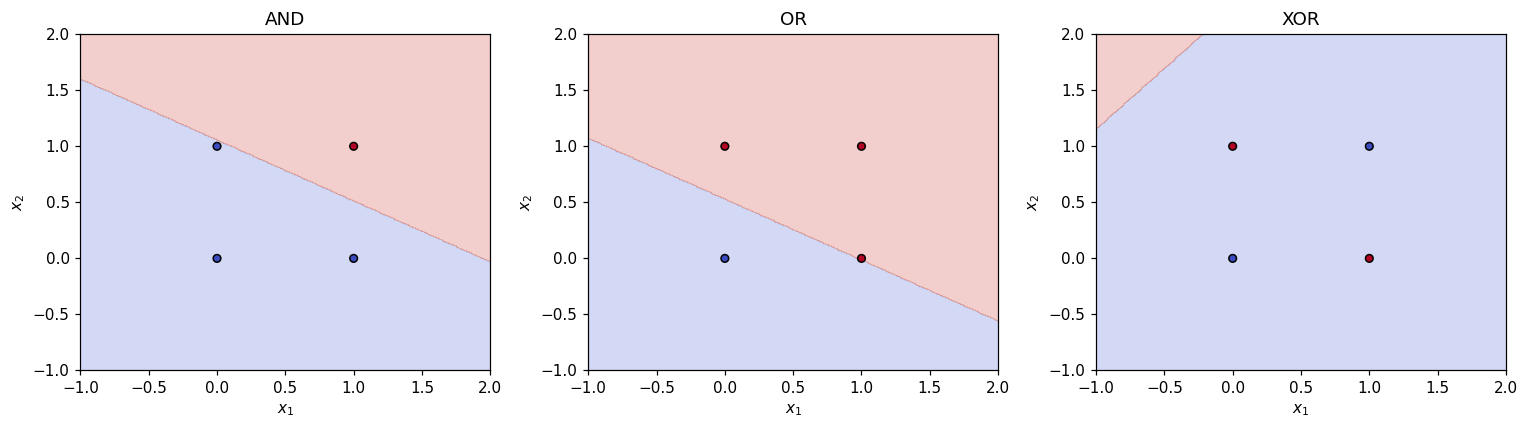

In [ ]:
X_logic = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
gates = {"AND": [0, 0, 0, 1], "OR": [0, 1, 1, 1], "XOR": [0, 1, 1, 0]}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, y_gate) in zip(axes, gates.items()):
    y_gate = np.array(y_gate)
    gate_model = Perceptron(learning_rate=0.1, n_epochs=100).fit(X_logic, y_gate)
    print(f"{name:>3} | précision = {gate_model.score(X_logic, y_gate):.2f} | "
          f"convergence = {gate_model.converged_} | époques = {gate_model.n_epochs_run_} | "
          f"prédictions = {gate_model.predict(X_logic)}")
    plot_decision_boundary(gate_model, X_logic, y_gate, title=name, ax=ax)
plt.tight_layout()
plt.show()

# Tests automatiques
for name in ["AND", "OR"]:
    y_gate = np.array(gates[name])
    m = Perceptron(learning_rate=0.1, n_epochs=100).fit(X_logic, y_gate)
    assert m.converged_ and m.score(X_logic, y_gate) == 1.0, f"{name} devrait être appris"
m_xor = Perceptron(learning_rate=0.1, n_epochs=100).fit(X_logic, np.array(gates["XOR"]))
assert not m_xor.converged_ and m_xor.score(X_logic, np.array(gates["XOR"])) < 1.0, "XOR ne doit pas être appris"
print("Tests réussis : AND et OR appris, XOR impossible.")

**Interprétation :** les portes AND et OR sont apprises parfaitement en quelques époques : une droite suffit à séparer les deux classes. Pour XOR, le modèle ne converge pas et sa précision reste inférieure à 100 % : les points de classe 1, (0,1) et (1,0), sont en diagonale opposée à ceux de classe 0, (0,0) et (1,1), et aucune droite ne peut les séparer. Ces trois résultats sont exactement ceux prévus par la théorie, ce qui **valide notre implémentation** (règle de mise à jour, biais, échelon, critère d'arrêt).

---
# 3. Test sur des données factices séparables

On génère deux nuages de points gaussiens bien distincts avec `make_blobs`. La séparation train/test se fait **avant** tout entraînement, de façon stratifiée pour conserver les proportions de classes.

Train : (400, 2) | Test : (100, 2)
Répartition des classes (train) : [200 200]


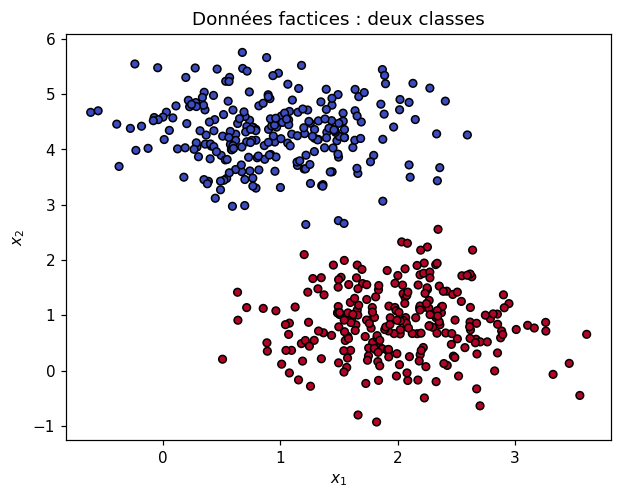

In [ ]:
X, y = make_blobs(n_samples=500, centers=2, n_features=2, cluster_std=0.6, random_state=RANDOM_STATE)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Répartition des classes (train) :", np.bincount(y_train))

plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=25)
plt.title("Données factices : deux classes")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$")
plt.show()

Convergence : True en 7 époques
Précision train : 1.000
Précision test  : 1.000
Poids : [ 0.74384807 -0.74640633] | Biais : 0.800


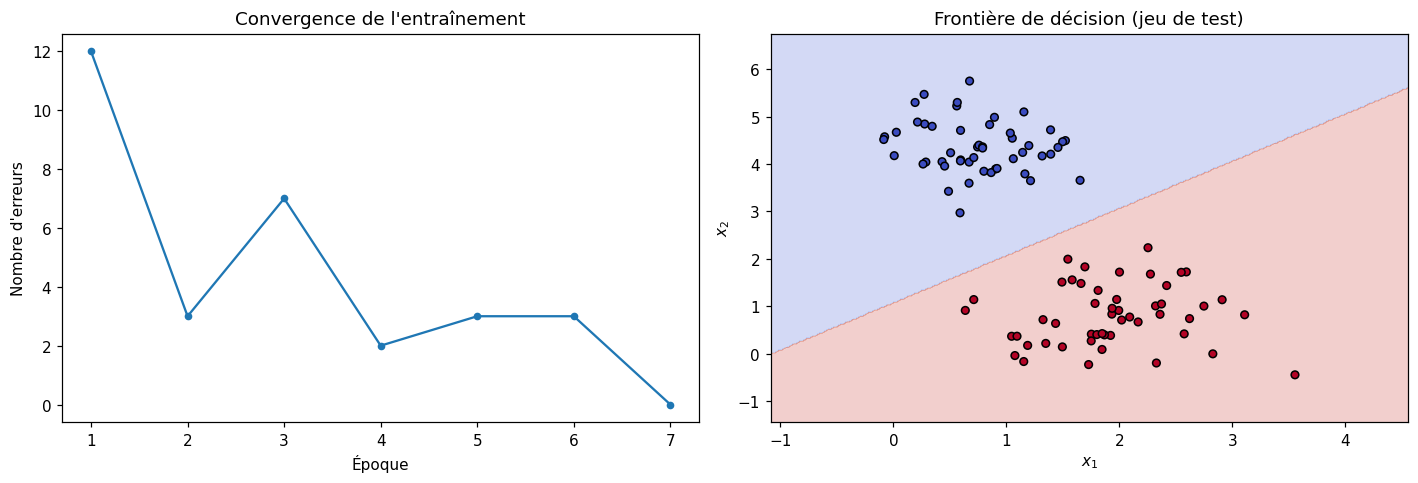

In [ ]:
model = Perceptron(learning_rate=0.1, n_epochs=100, random_state=42)
model.fit(X_train, y_train)

print(f"Convergence : {model.converged_} en {model.n_epochs_run_} époques")
print(f"Précision train : {model.score(X_train, y_train):.3f}")
print(f"Précision test  : {model.score(X_test, y_test):.3f}")
print(f"Poids : {model.weights_} | Biais : {model.bias_:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_convergence(model, ax=axes[0])
plot_decision_boundary(model, X_test, y_test, title="Frontière de décision (jeu de test)", ax=axes[1])
plt.tight_layout()
plt.show()

**Interprétation :**

- **Courbe de convergence** : le nombre d'erreurs par époque diminue puis tombe à **zéro**, ce qui déclenche l'arrêt anticipé. C'est le comportement garanti par le théorème de convergence sur des données linéairement séparables. Les erreurs ne décroissent pas de façon parfaitement monotone : le Perceptron corrige un exemple à la fois, et une correction peut en dégrader un autre temporairement.
- **Frontière de décision** : la droite d'équation $w_1 x_1 + w_2 x_2 + b = 0$ sépare nettement les deux nuages, y compris sur les données de test que le modèle n'a jamais vues.
- **Précision** : 100 % en train et en test. Ce résultat est attendu ici car les classes sont bien séparées ; il ne faudra pas s'attendre à un tel score sur des données réelles.

---
# 4. Influence du taux d'apprentissage et de l'initialisation

On entraîne le modèle avec plusieurs valeurs de $\eta$, puis avec plusieurs graines aléatoires.

In [ ]:
rows = []
for eta in [0.001, 0.01, 0.1, 1.0]:
    m = Perceptron(learning_rate=eta, n_epochs=100).fit(X_train, y_train)
    rows.append((eta, m.converged_, m.n_epochs_run_, m.score(X_test, y_test), np.linalg.norm(m.weights_)))

print(f"{'eta':>6} | {'converge':>8} | {'époques':>7} | {'précision test':>14} | {'norme des poids':>15}")
for eta, conv, n_ep, acc, norm in rows:
    print(f"{eta:>6} | {str(conv):>8} | {n_ep:>7} | {acc:>14.3f} | {norm:>15.4f}")

print()
print("Influence de la graine (eta = 0.1) :")
for seed in [1, 2, 3, 42]:
    m = Perceptron(learning_rate=0.1, n_epochs=100, random_state=seed).fit(X_train, y_train)
    print(f"  graine {seed:>2} -> converge en {m.n_epochs_run_:>2} époques, précision test = {m.score(X_test, y_test):.3f}")

   eta | converge | époques | précision test | norme des poids
 0.001 |     True |       5 |          1.000 |          0.0115
  0.01 |     True |       9 |          1.000 |          0.1193
   0.1 |     True |       7 |          1.000 |          1.0538
   1.0 |     True |       4 |          1.000 |         11.1081

Influence de la graine (eta = 0.1) :
  graine  1 -> converge en 18 époques, précision test = 1.000
  graine  2 -> converge en  5 époques, précision test = 1.000
  graine  3 -> converge en  3 époques, précision test = 1.000
  graine 42 -> converge en  7 époques, précision test = 1.000


**Interprétation :**

- **Taux d'apprentissage** : sur des données séparables, **toutes les valeurs de $\eta$ convergent vers 100 % de précision**. La différence se voit dans la **norme des poids** : elle croît avec $\eta$. En effet, comme les poids partent d'une valeur proche de zéro, $\eta$ ne change presque que l'**échelle** de $\mathbf{w}$ et de $b$ (donc de $z$), pas la **direction** de l'hyperplan, qui seule détermine la classe prédite. Le nombre d'époques varie peu et de façon non monotone en $\eta$ : il dépend surtout de l'ordre dans lequel les exemples sont rencontrés.
- **Initialisation et mélange** : le nombre d'époques nécessaires change d'une graine à l'autre, mais le résultat final est toujours une séparation parfaite.
- **Conséquence pour la suite** : sur le jeu Breast Cancer Wisconsin, les données ne seront probablement pas parfaitement séparables. Il faudra donc fixer un nombre d'époques et ne pas compter sur l'arrêt anticipé.

---
# 5. Cas non séparables

On teste maintenant deux situations où la séparation linéaire parfaite est impossible :

1. **Classes qui se chevauchent** (même type de nuages mais très dispersés) ;
2. **Classes non linéaires** : `make_moons` (deux demi-lunes imbriquées).

Chevauchement | converge = False | erreurs à la dernière époque = 163 | précision test = 0.730
   Demi-lunes | converge = False | erreurs à la dernière époque = 69 | précision test = 0.800


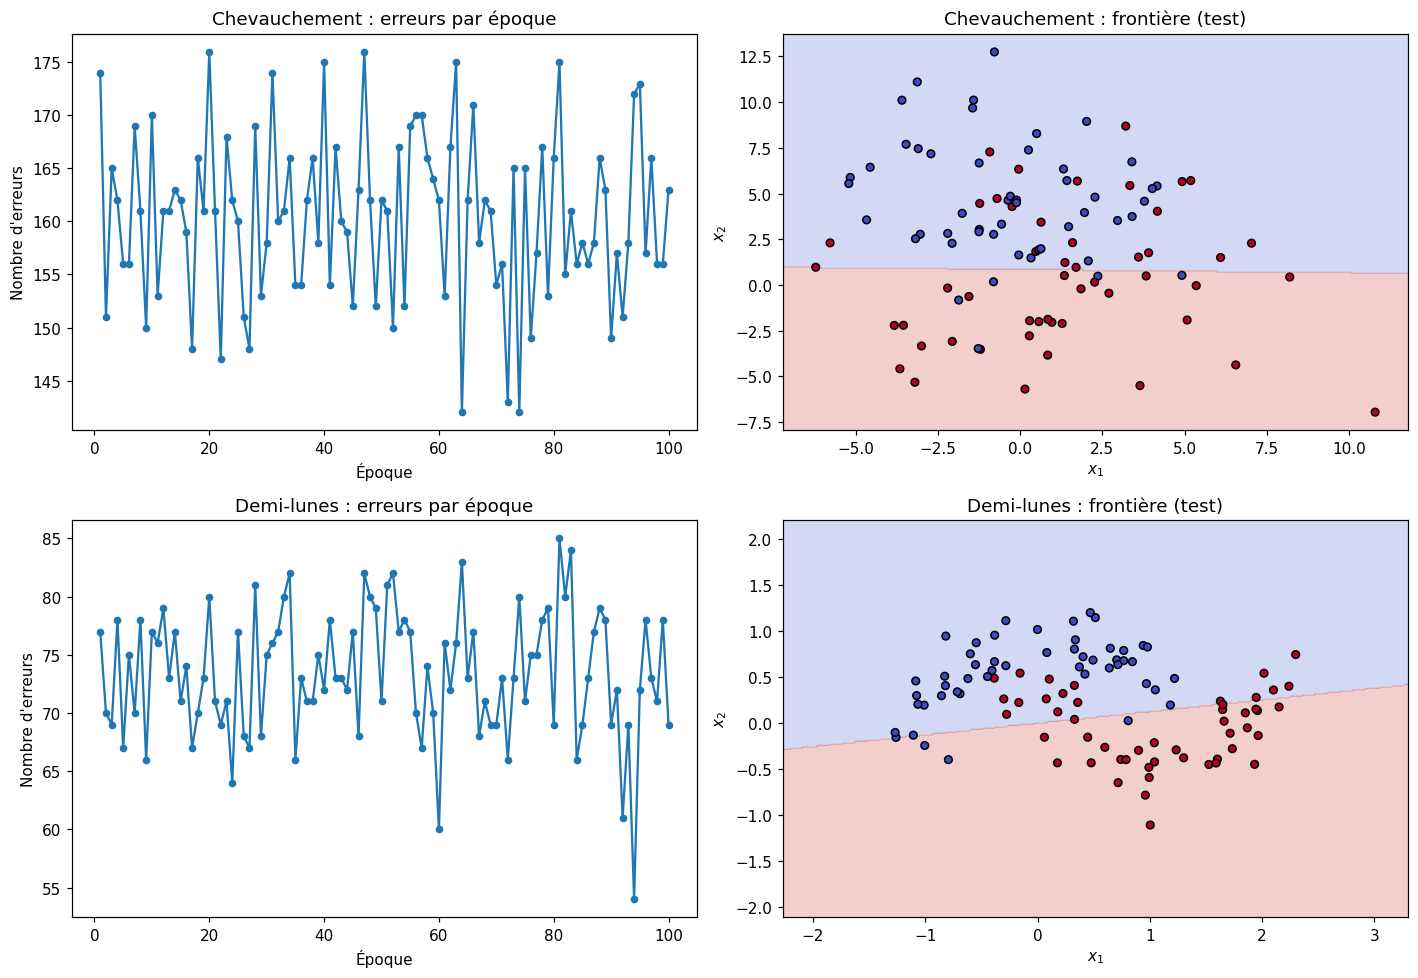

In [ ]:
# Cas 1 : nuages très dispersés qui se chevauchent
X_o, y_o = make_blobs(n_samples=500, centers=2, cluster_std=3.5, random_state=RANDOM_STATE)
Xo_tr, Xo_te, yo_tr, yo_te = train_test_split(X_o, y_o, test_size=0.2, random_state=RANDOM_STATE, stratify=y_o)
m_overlap = Perceptron(learning_rate=0.1, n_epochs=100).fit(Xo_tr, yo_tr)

# Cas 2 : demi-lunes
X_m, y_m = make_moons(n_samples=500, noise=0.2, random_state=RANDOM_STATE)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(X_m, y_m, test_size=0.2, random_state=RANDOM_STATE, stratify=y_m)
m_moons = Perceptron(learning_rate=0.1, n_epochs=100).fit(Xm_tr, ym_tr)

for name, m, Xte, yte in [("Chevauchement", m_overlap, Xo_te, yo_te), ("Demi-lunes", m_moons, Xm_te, ym_te)]:
    print(f"{name:>13} | converge = {m.converged_} | erreurs à la dernière époque = {m.errors_[-1]} "
          f"| précision test = {m.score(Xte, yte):.3f}")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plot_convergence(m_overlap, "Chevauchement : erreurs par époque", ax=axes[0, 0])
plot_decision_boundary(m_overlap, Xo_te, yo_te, "Chevauchement : frontière (test)", ax=axes[0, 1])
plot_convergence(m_moons, "Demi-lunes : erreurs par époque", ax=axes[1, 0])
plot_decision_boundary(m_moons, Xm_te, ym_te, "Demi-lunes : frontière (test)", ax=axes[1, 1])
plt.tight_layout()
plt.show()

**Interprétation :**

- **Chevauchement** : le modèle **ne converge pas dans la limite de 100 époques** : le nombre d'erreurs par époque reste élevé (autour de 150 sur 400) et fluctue sans se stabiliser. Avec un tel recouvrement visible sur le graphique, la non-séparabilité est très probable, mais seul un test exact (programmation linéaire, utilisé dans la partie suivante) le démontre. Les exemples situés dans la zone de recouvrement entraînent des corrections contradictoires qui déplacent sans cesse la droite. La précision en test est nettement plus faible (environ 73 % ici) et c'est le résultat de la **dernière** mise à jour, pas forcément du meilleur jeu de poids rencontré.
- **Demi-lunes** : la structure des classes est non linéaire, et une droite ne peut qu'en donner une approximation grossière (environ 80 % de précision en test). Le modèle est trop simple pour la forme des données : on parle de **sous-apprentissage** (biais élevé).
- **Enseignement** : la précision du Perceptron dépend directement de la **séparabilité linéaire** des données. Les pistes pour dépasser cette limite, que nous évoquerons dans la conclusion du projet, sont notamment de garder les meilleurs poids rencontrés pendant l'entraînement (algorithme *pocket*), d'ajouter des couches avec activations non linéaires (MLP), ou de changer de modèle.

---
# 6. Comparaison avec scikit-learn

Pour valider l'implémentation, on la compare à `sklearn.linear_model.Perceptron` sur les données séparables. Les deux utilisent la même règle d'apprentissage ; on désactive le critère d'arrêt `tol` de scikit-learn pour qu'il s'entraîne autant d'époques que le nôtre.

In [ ]:
from sklearn.linear_model import Perceptron as SkPerceptron

sk_model = SkPerceptron(eta0=0.1, max_iter=100, tol=None, shuffle=True, random_state=0)
sk_model.fit(X_train, y_train)

pred_ours = model.predict(X_test)
pred_sk = sk_model.predict(X_test)

print(f"Précision test, notre Perceptron : {model.score(X_test, y_test):.3f}")
print(f"Précision test, scikit-learn     : {sk_model.score(X_test, y_test):.3f}")
print(f"Accord entre les prédictions     : {np.mean(pred_ours == pred_sk):.3f}")

Précision test, notre Perceptron : 1.000
Précision test, scikit-learn     : 1.000
Accord entre les prédictions     : 1.000


**Interprétation :** les deux modèles atteignent la même précision et leurs prédictions concordent. Les poids exacts ne sont pas identiques (initialisation et ordre de mélange différents, et plusieurs hyperplans séparent correctement les mêmes données), mais ils définissent des frontières équivalentes pour la classification. Notre implémentation se comporte donc comme la référence.

---
# 7. Robustesse : gestion des erreurs

On vérifie que la classe refuse les utilisations incorrectes avec un message explicite.

In [ ]:
def expect_error(error_type, func, label):
    try:
        func()
    except error_type as e:
        print(f"[OK] {label} -> {error_type.__name__} : {e}")
    else:
        raise AssertionError(f"{label} aurait dû lever {error_type.__name__}")

expect_error(ValueError, lambda: Perceptron(learning_rate=-0.1), "taux d'apprentissage négatif")
expect_error(ValueError, lambda: Perceptron(n_epochs=0), "zéro époque")
expect_error(RuntimeError, lambda: Perceptron().predict(X_test), "prédiction avant entraînement")
expect_error(ValueError, lambda: Perceptron().fit(X_train, y_train + 1), "étiquettes différentes de 0 et 1")
expect_error(ValueError, lambda: Perceptron().fit(X_train, y_train[:-1]), "X et y de tailles différentes")
expect_error(ValueError, lambda: Perceptron().fit(X_train[:, 0], y_train), "X à une seule dimension")

[OK] taux d'apprentissage négatif -> ValueError : learning_rate doit être strictement positif.
[OK] zéro époque -> ValueError : n_epochs doit être supérieur ou égal à 1.
[OK] prédiction avant entraînement -> RuntimeError : Le modèle n'est pas entraîné : appelez d'abord fit(X, y).
[OK] étiquettes différentes de 0 et 1 -> ValueError : y doit contenir uniquement les valeurs 0 et 1.
[OK] X et y de tailles différentes -> ValueError : X et y doivent contenir le même nombre d'exemples.
[OK] X à une seule dimension -> ValueError : X doit être un tableau à 2 dimensions (n_samples, n_features).


---
# 8. Conclusion

**Ce que nous avons fait**
- Implémenté en programmation orientée objet un Perceptron avec activation échelon, règle d'apprentissage de Rosenblatt, mélange des données, arrêt anticipé et suivi des erreurs.
- Validé la classe sur AND, OR (appris) et XOR (impossible), conformément à la théorie.
- Testé sur des données factices : convergence rapide et frontière correcte sur des classes séparables, absence de convergence sur des classes qui se chevauchent, performances limitées sur des classes non linéaires.
- Vérifié que notre modèle se comporte comme celui de scikit-learn.

**Ce que cela implique pour la partie suivante**
- Le Perceptron fonctionne bien **si les classes sont (quasi) linéairement séparables**. L'analyse exploratoire du jeu Breast Cancer Wisconsin nous dira si c'est le cas.
- Il faudra **standardiser** les variables (échelles très différentes), fixer un **nombre d'époques** raisonnable et choisir des **métriques** adaptées au contexte médical (rappel, matrice de confusion) plutôt que la seule précision.
- Le modèle ne fournit pas de probabilités : pour la courbe ROC, on utilisera `net_input` comme score.

La classe `Perceptron` est maintenant prête à être appliquée aux données réelles.